PARTE A: MÉDIA MÓVEL COM M = 3
Equação de diferenças:
  y[n] = (1/3) (x[n] + x[n-1] + x[n-2])
Coeficientes: b = [0.3333 0.3333 0.3333]
Resposta ao impulso (lfilter):   [0.3333 0.3333 0.3333 0.     0.     0.     0.     0.    ]
Resposta ao impulso (forma direta): [0.3333 0.3333 0.3333 0.     0.     0.     0.     0.    ]
Erro lfilter x forma direta: 0.00e+00
Função de transferência: H(z) = (1/3)(1 + z^-1 + z^-2) = (z^2 + z + 1) / (3 z^2)
Zeros: [-0.5+0.866j -0.5-0.866j]  (módulo [1. 1.], ângulo ±120.0°)
Polos: z = 0 (multiplicidade 2)  -> todos na origem
Erro H(e^jw) definição x scipy.freqz: 3.14e-16
|H(1)| = 1.0000 | corte -3 dB: 0.9756 rad (0.311π) | zero de |H| em 2π/3 = 0.667π
Fase (primeiro lóbulo): -(M-1)/2 · ω = -ω rad  (atraso de 1 amostra)

PARTE B: CARACTERÍSTICAS FIR DA MÉDIA MÓVEL
   M  ordem M-1  nº coef.   Σ|h[n]|  estável  atraso (am.)  mult/saída  soma/saída  soma/saída (recursiva)
--------------------------------------------------------------------------------------------

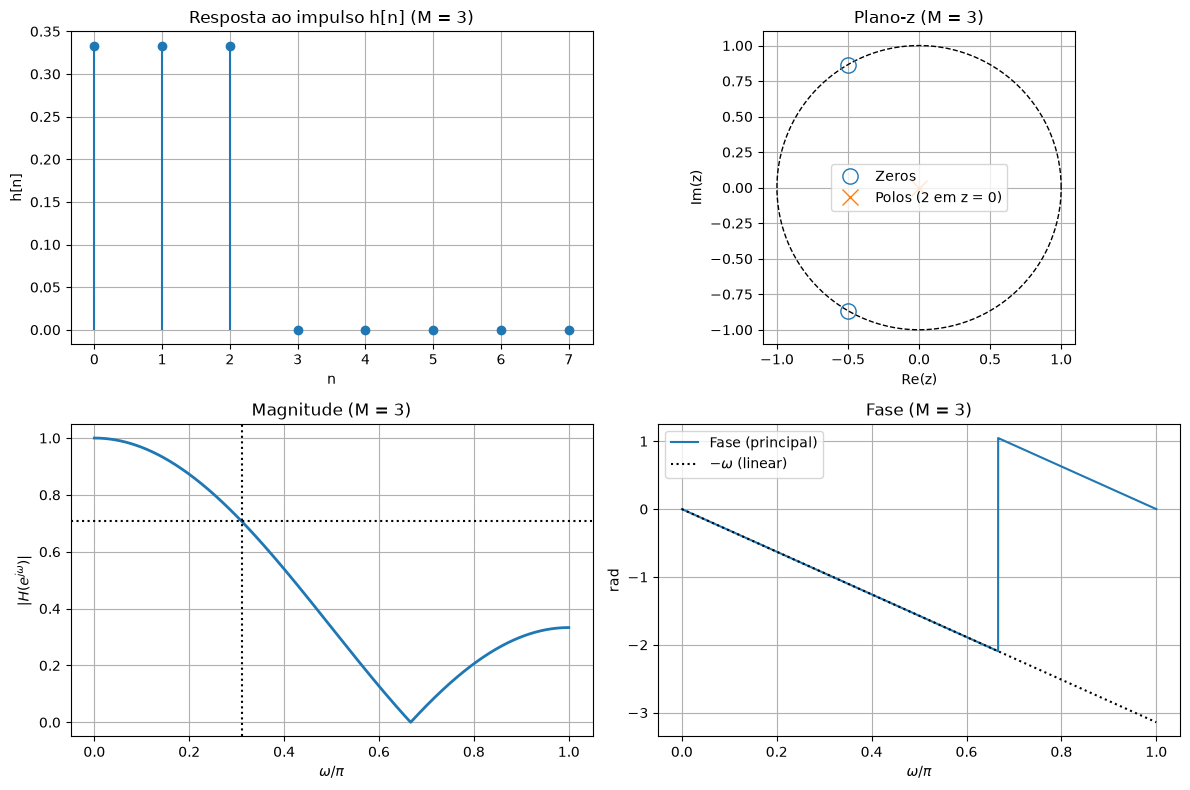

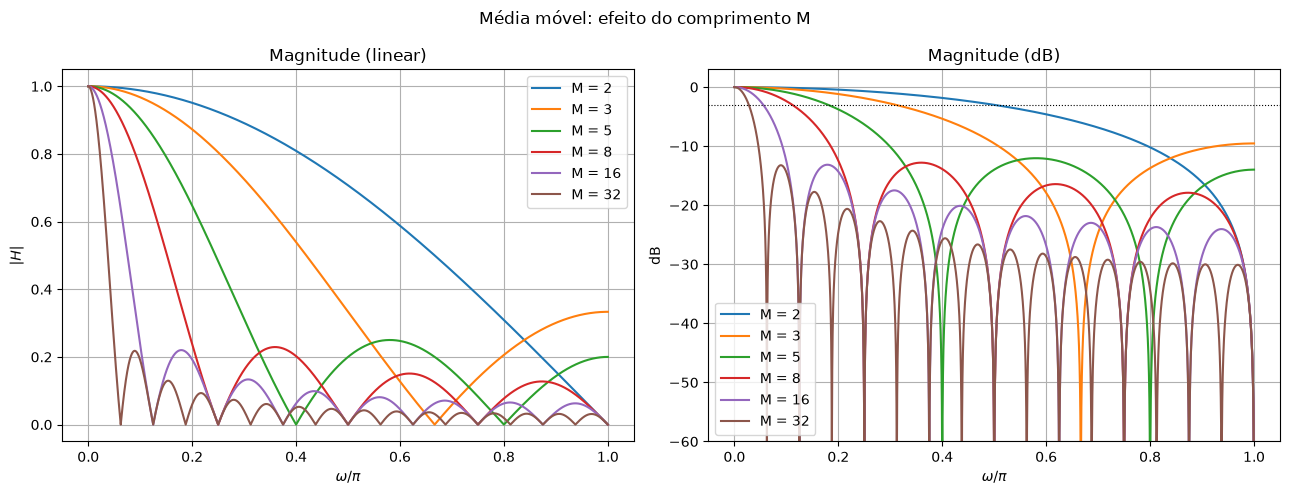

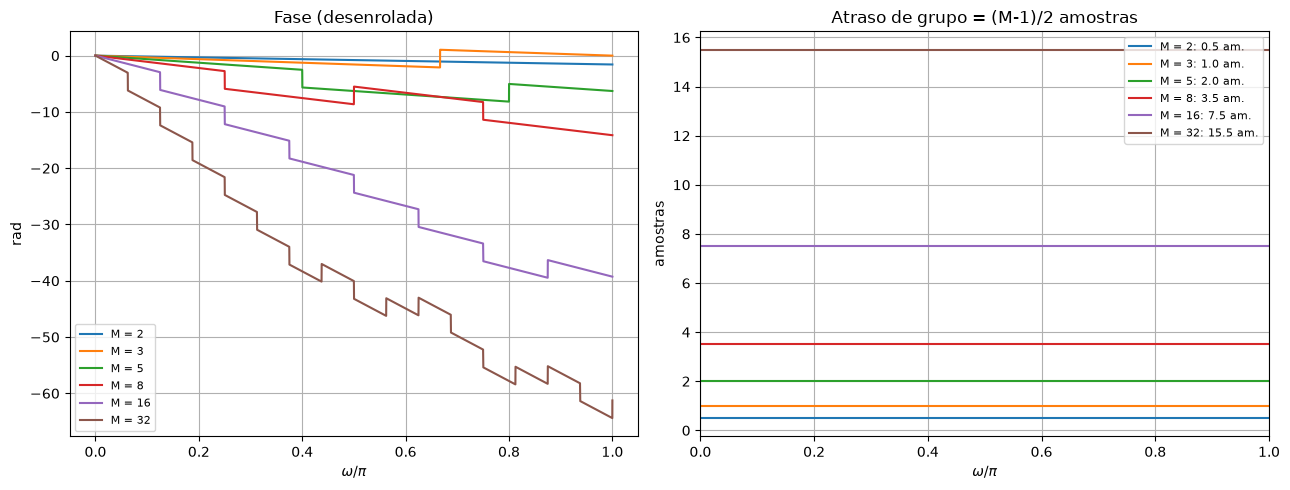

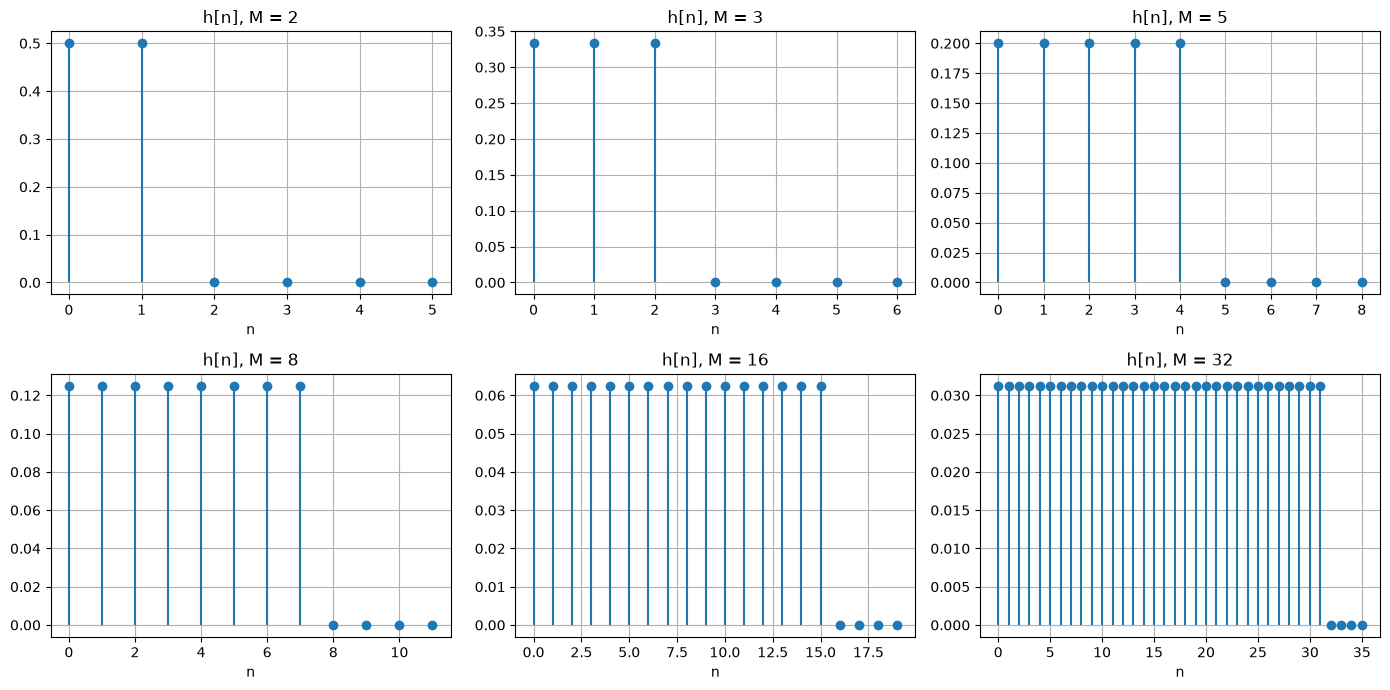

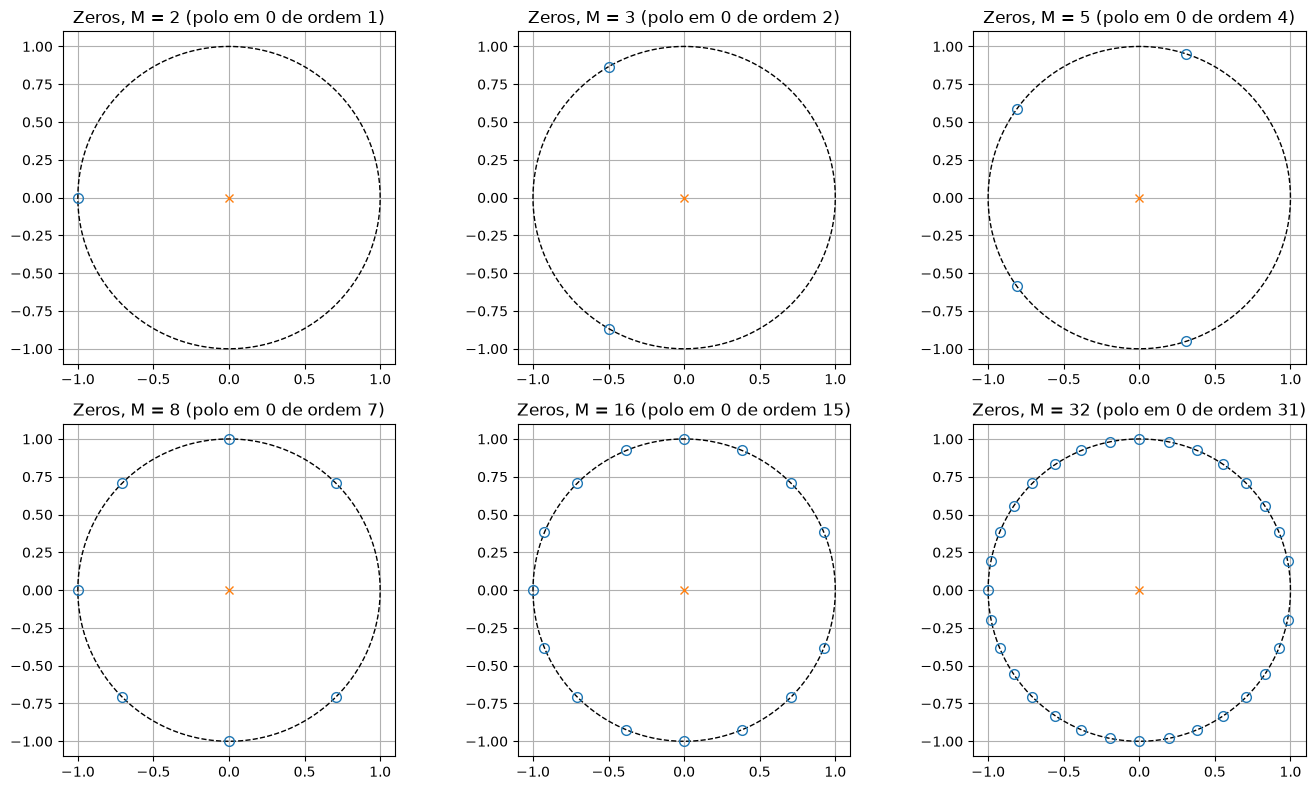

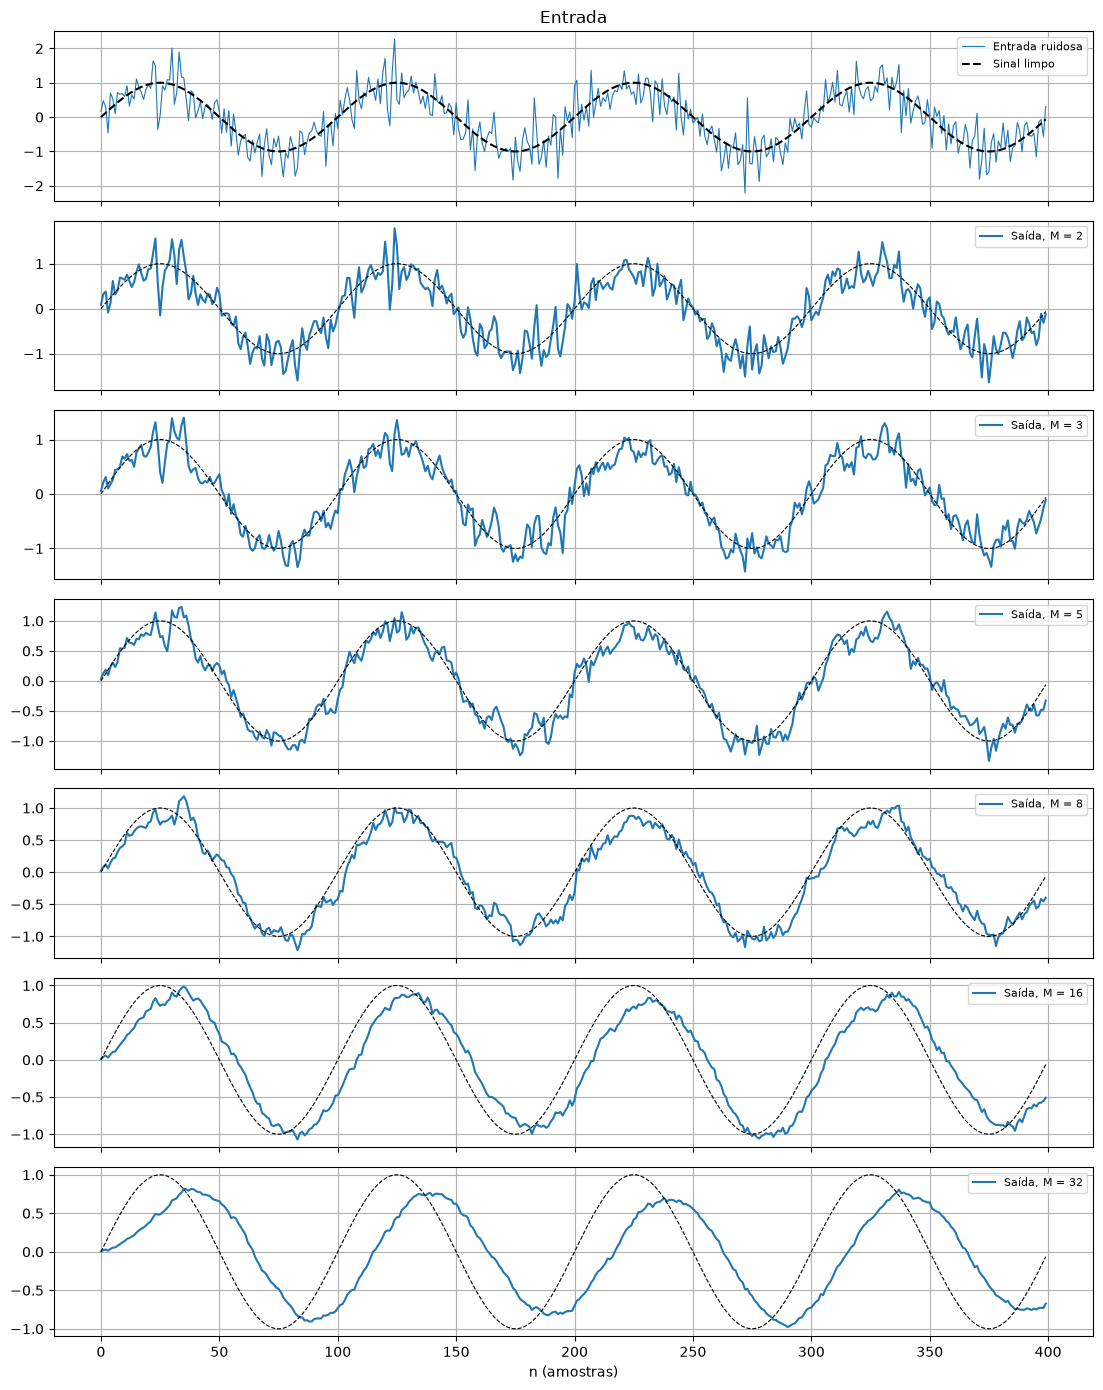


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 4: Filtros FIR (média móvel)

    y[n] = sum_{k=0}^{M-1} b_k x[n-k],   h[n] = (1/M){1, 1, ..., 1}
    H(z) = (1/M) sum_{k=0}^{M-1} z^-k

Parte A (M = 3, exemplo do roteiro): equação de diferenças, resposta ao
impulso, função de transferência, polos e zeros, magnitude e fase.
Parte B: características FIR (resposta finita, ausência de realimentação,
ordem, estabilidade, fase linear, nº de coeficientes, custo computacional).
Parte C: comparação de vários valores de M.

Convenção: ω em rad/amostra; eixo em Hz usa fs = 1000 Hz.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000.0
w = np.linspace(0, np.pi, 8001)


# ============================================================
# FUNÇÕES AUXILIARES
# ============================================================

def coef_media_movel(M):
    return np.ones(M) / M


def fir_direto(b, x):
    """Forma direta FIR: y[n] = sum_k b[k] x[n-k], sem realimentação."""
    M = len(b)
    y = np.zeros(len(x))
    for n in range(len(x)):
        for k in range(M):
            if n - k >= 0:
                y[n] += b[k] * x[n - k]
    return y


def resposta_em_frequencia(b, w):
    """H(e^{jw}) = sum_k b[k] e^{-jwk} (definição)."""
    k = np.arange(len(b))
    return np.exp(-1j * np.outer(w, k)) @ b


def freq_corte_3db(mag, w):
    i = np.argmax(mag <= mag[0] / np.sqrt(2))
    return np.interp(mag[0] / np.sqrt(2), [mag[i], mag[i - 1]],
                     [w[i], w[i - 1]])


def pico_lobulo_lateral_db(mag, w, M):
    """Maior lóbulo lateral (dB relativo ao ganho DC), w >= 2π/M."""
    reg = w >= 2 * np.pi / M
    # M = 2: o 1º zero está em π e não há lóbulo lateral
    return 20 * np.log10(mag[reg].max() / mag[0]) if M > 2 else np.nan


# ============================================================
# PARTE A: MÉDIA MÓVEL COM M = 3
# ============================================================

M3 = 3
b3 = coef_media_movel(M3)

print("PARTE A: MÉDIA MÓVEL COM M = 3")
print("=" * 70)
print("Equação de diferenças:")
print("  y[n] = (1/3) (x[n] + x[n-1] + x[n-2])")
print(f"Coeficientes: b = {np.round(b3, 4)}")

# Resposta ao impulso: por lfilter e pela forma direta
N_h = 8
delta = np.zeros(N_h)
delta[0] = 1.0
h_lf = signal.lfilter(b3, [1.0], delta)
h_dir = fir_direto(b3, delta)
print(f"Resposta ao impulso (lfilter):   {np.round(h_lf, 4)}")
print(f"Resposta ao impulso (forma direta): {np.round(h_dir, 4)}")
print(f"Erro lfilter x forma direta: {np.max(np.abs(h_lf - h_dir)):.2e}")

print("Função de transferência: H(z) = (1/3)(1 + z^-1 + z^-2)"
      " = (z^2 + z + 1) / (3 z^2)")
zeros3 = np.roots(b3)              # zeros: raízes de z^2 + z + 1
print(f"Zeros: {np.round(zeros3, 4)}  (módulo {np.abs(zeros3).round(3)}, "
      f"ângulo ±{np.degrees(np.abs(np.angle(zeros3[0]))):.1f}°)")
print(f"Polos: z = 0 (multiplicidade {M3 - 1})  -> todos na origem")

H3 = resposta_em_frequencia(b3, w)
_, H3_sp = signal.freqz(b3, [1.0], worN=w)
print(f"Erro H(e^jw) definição x scipy.freqz: {np.max(np.abs(H3 - H3_sp)):.2e}")
mag3 = np.abs(H3)
wc3 = freq_corte_3db(mag3, w)
print(f"|H(1)| = {mag3[0]:.4f} | corte -3 dB: {wc3:.4f} rad "
      f"({wc3 / np.pi:.3f}π) | zero de |H| em 2π/3 = {2 / 3:.3f}π")
print("Fase (primeiro lóbulo): -(M-1)/2 · ω = -ω rad  (atraso de 1 amostra)")

# ============================================================
# PARTE B: CARACTERÍSTICAS DOS FILTROS FIR (para vários M)
# ============================================================

Ms = [2, 3, 5, 8, 16, 32]

print("\nPARTE B: CARACTERÍSTICAS FIR DA MÉDIA MÓVEL")
print("=" * 98)
print(f"{'M':>4}{'ordem M-1':>11}{'nº coef.':>10}{'Σ|h[n]|':>10}"
      f"{'estável':>9}{'atraso (am.)':>14}{'mult/saída':>12}"
      f"{'soma/saída':>12}{'soma/saída (recursiva)':>24}")
print("-" * 98)
for M in Ms:
    b = coef_media_movel(M)
    print(f"{M:>4}{M - 1:>11}{M:>10}{np.sum(np.abs(b)):>10.3f}"
          f"{'sim':>9}{(M - 1) / 2:>14.1f}{M:>12}{M - 1:>12}{2:>24}")
print("(Σ|h| finito para qualquer FIR: estabilidade BIBO garantida. A forma "
      "recursiva\n y[n] = y[n-1] + (x[n]-x[n-M])/M usa 2 somas e 1 mult. por "
      "saída, mas tem polo em z = 1 cancelado por um zero.)")

# Fase linear: simetria dos coeficientes
for M in (3, 8):
    b = coef_media_movel(M)
    print(f"M = {M}: b simétrico (b[k] = b[M-1-k]): "
          f"{np.allclose(b, b[::-1])}")

# Medida do custo computacional (tempo para filtrar 1e5 amostras)
import time
x_teste = np.random.default_rng(0).standard_normal(100_000)
print("\nTempo para filtrar 1e5 amostras (scipy.signal.lfilter, média de 5):")
for M in Ms:
    b = coef_media_movel(M)
    t_ms = []
    signal.lfilter(b, [1.0], x_teste)   # aquecimento
    for _ in range(5):
        t0 = time.perf_counter()
        signal.lfilter(b, [1.0], x_teste)
        t_ms.append(1e3 * (time.perf_counter() - t0))
    print(f"  M = {M:>3}: {np.mean(t_ms):.3f} ms")
print("(Tempos dependem da máquina; servem só como ordem de grandeza.)")

# ============================================================
# PARTE C: COMPARAÇÃO ENTRE VALORES DE M
# ============================================================

print("\nPARTE C: COMPARAÇÃO ENTRE VALORES DE M")
print("=" * 86)
print(f"{'M':>4}{'wc (-3 dB) / π':>16}{'wc (Hz)':>10}{'1º zero 2π/M ÷ π':>20}"
      f"{'largura trans.(π)':>20}{'lóbulo lateral (dB)':>20}")
print("-" * 86)
resultados = {}
for M in Ms:
    b = coef_media_movel(M)
    H = resposta_em_frequencia(b, w)
    mag = np.abs(H)
    wc = freq_corte_3db(mag, w)
    w_z = 2 * np.pi / M
    lob = pico_lobulo_lateral_db(mag, w, M)
    resultados[M] = (H, wc)
    print(f"{M:>4}{wc / np.pi:>16.4f}{wc * fs / (2 * np.pi):>10.1f}"
          f"{w_z / np.pi:>20.4f}{(w_z - wc) / np.pi:>20.4f}"
          f"{('—' if np.isnan(lob) else f'{lob:.2f}'):>20}")

print("\nVerificação: forma fechada |sin(Mw/2)/(M sin(w/2))| x definição")
for M in Ms:
    with np.errstate(invalid="ignore", divide="ignore"):
        fech = np.abs(np.sin(M * w / 2) / (M * np.sin(w / 2)))
    fech[0] = 1.0
    print(f"  M = {M:>2}: erro máx. = {np.max(np.abs(fech - np.abs(resultados[M][0]))):.2e}")

# Efeito prático: ruído branco + senoide lenta
rng = np.random.default_rng(1)
n = np.arange(400)
sinal_limpo = np.sin(2 * np.pi * 0.01 * n)
ruido = 0.5 * rng.standard_normal(len(n))
x_ruidoso = sinal_limpo + ruido
print("\nRedução de ruído (senoide 0,01 ciclos/amostra + ruído branco σ = 0,5):")
print(f"{'M':>4}{'REQM vs. sinal limpo':>24}{'ruído residual teórico σ/√M':>30}")
print(f"{'—':>4}{np.sqrt(np.mean(ruido ** 2)):>24.4f}{'(sem filtro)':>30}")
saidas = {}
for M in Ms:
    y = signal.lfilter(coef_media_movel(M), [1.0], x_ruidoso)
    saidas[M] = y
    # alinha o atraso de (M-1)/2 para comparar com o sinal limpo
    atraso = (M - 1) / 2
    ref = np.sin(2 * np.pi * 0.01 * (n - atraso))
    reg = n >= M
    reqm = np.sqrt(np.mean((y[reg] - ref[reg]) ** 2))
    print(f"{M:>4}{reqm:>24.4f}{0.5 / np.sqrt(M):>30.4f}")

# ============================================================
# FIGURAS
# ============================================================

# Fig. 1: M = 3 - h[n], zeros/polos, magnitude e fase
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
eixos[0, 0].stem(np.arange(N_h), h_lf, basefmt=" ")
eixos[0, 0].set_title("Resposta ao impulso h[n] (M = 3)")
eixos[0, 0].set_xlabel("n")
eixos[0, 0].set_ylabel("h[n]")
eixos[0, 0].grid(True)

ax = eixos[0, 1]
th = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
ax.plot(zeros3.real, zeros3.imag, "o", markerfacecolor="none",
        markersize=11, label="Zeros")
ax.plot([0], [0], "x", markersize=12, label="Polos (2 em z = 0)")
ax.set_aspect("equal")
ax.set_title("Plano-z (M = 3)")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.legend()
ax.grid(True)

eixos[1, 0].plot(w / np.pi, mag3, linewidth=2)
eixos[1, 0].axhline(1 / np.sqrt(2), color="k", linestyle=":")
eixos[1, 0].axvline(wc3 / np.pi, color="k", linestyle=":")
eixos[1, 0].set_title("Magnitude (M = 3)")
eixos[1, 0].set_xlabel(r"$\omega/\pi$")
eixos[1, 0].set_ylabel(r"$|H(e^{j\omega})|$")
eixos[1, 0].grid(True)

eixos[1, 1].plot(w / np.pi, np.angle(H3), label="Fase (principal)")
eixos[1, 1].plot(w / np.pi, -w, "k:", label=r"$-\omega$ (linear)")
eixos[1, 1].set_title("Fase (M = 3)")
eixos[1, 1].set_xlabel(r"$\omega/\pi$")
eixos[1, 1].set_ylabel("rad")
eixos[1, 1].legend()
eixos[1, 1].grid(True)
plt.tight_layout()
plt.show()

# Fig. 2: comparação das magnitudes (linear e dB)
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for M in Ms:
    mag = np.abs(resultados[M][0])
    eixos[0].plot(w / np.pi, mag, label=f"M = {M}")
    eixos[1].plot(w / np.pi, 20 * np.log10(np.maximum(mag, 1e-6)),
                  label=f"M = {M}")
eixos[0].set_ylabel(r"$|H|$")
eixos[0].set_title("Magnitude (linear)")
eixos[1].set_ylabel("dB")
eixos[1].set_ylim(-60, 3)
eixos[1].axhline(-3.01, color="k", linestyle=":", linewidth=0.8)
eixos[1].set_title("Magnitude (dB)")
for ax in eixos:
    ax.set_xlabel(r"$\omega/\pi$")
    ax.grid(True)
    ax.legend()
plt.suptitle("Média móvel: efeito do comprimento M")
plt.tight_layout()
plt.show()

# Fig. 3: fase e atraso de grupo para vários M
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for M in Ms:
    eixos[0].plot(w / np.pi, np.unwrap(np.angle(resultados[M][0])),
                  label=f"M = {M}")
    eixos[1].axhline((M - 1) / 2, label=f"M = {M}: {(M - 1) / 2} am.",
                     color=f"C{Ms.index(M)}")
eixos[0].set_title("Fase (desenrolada)")
eixos[0].set_ylabel("rad")
eixos[1].set_title("Atraso de grupo = (M-1)/2 amostras")
eixos[1].set_ylabel("amostras")
for ax in eixos:
    ax.set_xlabel(r"$\omega/\pi$")
    ax.grid(True)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Fig. 4: respostas ao impulso e zeros para vários M
fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for ax, M in zip(eixos.ravel(), Ms):
    ax.stem(np.arange(M + 4), np.r_[coef_media_movel(M), np.zeros(4)],
            basefmt=" ")
    ax.set_title(f"h[n], M = {M}")
    ax.set_xlabel("n")
    ax.grid(True)
plt.tight_layout()
plt.show()

fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for ax, M in zip(eixos.ravel(), Ms):
    zs = np.exp(2j * np.pi * np.arange(1, M) / M)
    ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
    ax.plot(zs.real, zs.imag, "o", markerfacecolor="none", markersize=7)
    ax.plot([0], [0], "x")
    ax.set_aspect("equal")
    ax.set_title(f"Zeros, M = {M} (polo em 0 de ordem {M - 1})")
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 5: filtragem de sinal ruidoso
fig, eixos = plt.subplots(len(Ms) + 1, 1, figsize=(11, 14), sharex=True)
eixos[0].plot(n, x_ruidoso, linewidth=0.8, label="Entrada ruidosa")
eixos[0].plot(n, sinal_limpo, "k--", label="Sinal limpo")
eixos[0].legend(loc="upper right", fontsize=8)
eixos[0].set_title("Entrada")
for ax, M in zip(eixos[1:], Ms):
    ax.plot(n, saidas[M], label=f"Saída, M = {M}")
    ax.plot(n, sinal_limpo, "k--", linewidth=0.8)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True)
eixos[0].grid(True)
eixos[-1].set_xlabel("n (amostras)")
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")